<a href="https://colab.research.google.com/github/Niveditha-28/drone_spraying_nsga2/blob/main/drone_spraying_nsga2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multi-Drone Precision Spraying Route Planning using NSGA-II

**Course assignment:** Evolutionary Computation / AI Optimization

**Domain:** Agriculture

**Team:** Niveditha S(RA2411047010028), Krishna Priya K U          (RA2411047010045)

**Technique:** NSGA-II (multi-objective evolutionary algorithm)




---
## 1. Problem statement

Modern farms use drones to spray pesticide and fertiliser. A fleet of **3 drones** must cover a **180 m x 180 m field** that contains
no-fly obstacles (a pond, tree clusters and a **power line with only two gaps**). Each drone has a **limited battery and tank**, so it must
return to the depot to swap/refill. **Wind** (blowing east) makes flying with the wind cheaper and against the wind more expensive.
Parts of the field are **disease hotspots** that should be treated first.

The field is divided into 6 x 6-cell **zones**. We must decide **which drone sprays which zone** and **in what order**.
Three goals conflict with each other, so we use a multi-objective algorithm and obtain a *Pareto front* instead of one answer:

| # | Objective (all minimised) | Meaning |
|---|---|---|
| f1 | **Total energy (Wh)** | flight (wind-aware) + spraying + extra trips back to the depot |
| f2 | **Priority-weighted delay (s)** | average time at which a zone is sprayed, weighted by disease severity (hotspots first) |
| f3 | **Mission time / makespan (s)** | time when the *last* drone lands (workload balance) |

### Why NSGA-II?
* There are **three conflicting objectives** and the farmer should be able to pick a trade-off, which is exactly what a Pareto front gives.
* The decision space is **combinatorial** (assignment + ordering), where population-based evolutionary search works well.
* NSGA-II (Deb et al., 2002) uses **non-dominated sorting + crowding distance**, which keeps a well spread front.

### Chromosome (multi-TSP encoding)
A permutation of `0 .. Z + D - 2`. Values `< Z` are zones; the `D-1` extra values are **separators** that cut the permutation into one route per drone.
Operators: **Order Crossover (OX)** and **Inversion mutation**, both of which always keep the chromosome a valid permutation.

In [2]:
# 2. Setup
!pip install pymoo -q
import numpy as np, pandas as pd, time, json, os
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle
from matplotlib.animation import FuncAnimation, PillowWriter
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import dijkstra
os.makedirs("results", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})
print("Setup done")

Setup done


## 2. Simulation parameters
Everything about the field, drones and energy model is defined here, so experiments are easy to repeat with different settings.
(Energy values are in **illustrative Wh**: the model is a simulation, not calibrated to a specific drone.)

In [3]:
SEED = 42
rng = np.random.default_rng(SEED)

N = 36                    # field is N x N cells
CELL = 5.0                # metres per cell -> 180 m x 180 m
ZB = 6                    # zone block size in cells -> 6 x 6 = 36 zones
N_DRONES = 3
SPEED = 8.0               # m/s cruise speed
SPRAY_T_PER_CELL = 3.0    # seconds to spray one cell
SPRAY_E_PER_CELL = 0.20   # Wh per sprayed cell
FLIGHT_E_PER_M = 0.25     # Wh per metre in still air
WIND = np.array([1.0, 0.0])   # wind blows towards +x (east)
WIND_EFFECT = 0.25        # tail wind: -25 % energy, head wind: +25 % energy
TURNAROUND_T = 60.0       # s for battery swap + tank refill at the depot
TANK_CELLS = 80           # tank capacity (in cells of area)
BATTERY_WH = 220.0        # battery energy per sortie

# NSGA-II settings
POP_SIZE = 200
N_GEN = 1000

## 3. Build the field, disease hotspots and zones

35 zones to spray, total sprayed area = 1190 cells, depot at (0, 0)


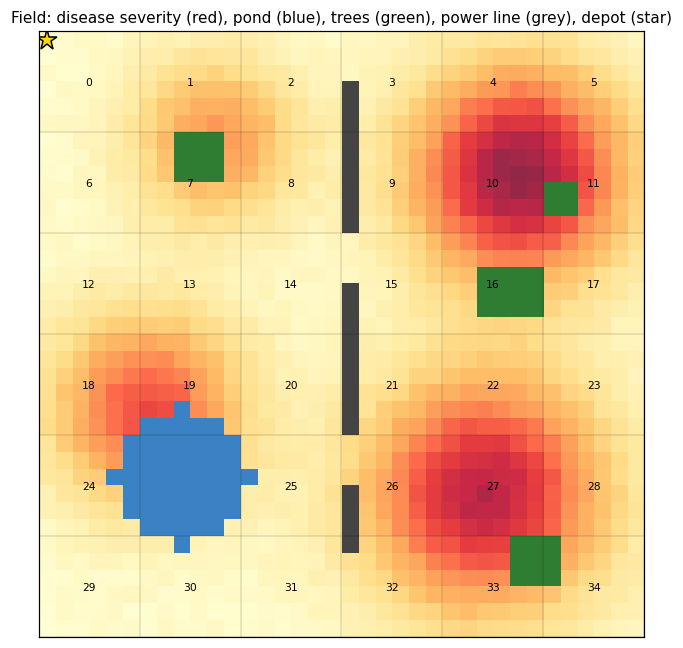

In [4]:
def build_field():
    kind = np.zeros((N, N), int)           # 0 free, 1 pond, 2 trees, 3 power line
    yy, xx = np.mgrid[0:N, 0:N]
    kind[(yy - 26) ** 2 + (xx - 8) ** 2 <= 16] = 1                      # pond
    for (r, c, h, w) in [(6, 8, 3, 3), (14, 26, 3, 4), (30, 28, 3, 3), (9, 30, 2, 2)]:
        kind[r:r + h, c:c + w] = 2                                         # tree clusters
    kind[3:31, 18] = 3                                                     # power line wall ...
    kind[12:15, 18] = 0                                                    # ... with gap 1
    kind[24:27, 18] = 0                                                    # ... and gap 2
    kind[0, 0] = 0                                                         # depot cell
    sev = np.zeros((N, N))                                                 # disease severity map 0..1
    for (r, c, s, a) in [(8, 28, 4.5, 1.0), (27, 26, 5.0, 0.9), (22, 6, 4.0, 0.7), (6, 10, 3.5, 0.5)]:
        sev += a * np.exp(-((yy - r) ** 2 + (xx - c) ** 2) / (2 * s ** 2))
    sev += 0.05 * rng.random((N, N))
    return kind, np.clip(sev / sev.max(), 0, 1)

kind, sev = build_field()
obst = kind > 0

zones = []
for zr in range(N // ZB):
    for zc in range(N // ZB):
        sl = (slice(zr * ZB, (zr + 1) * ZB), slice(zc * ZB, (zc + 1) * ZB))
        free = ~obst[sl]
        if free.sum() < 6:            # zone almost fully blocked -> skipped
            continue
        rr, cc = np.nonzero(free)
        k = np.argmin((rr - rr.mean()) ** 2 + (cc - cc.mean()) ** 2)
        zones.append(dict(zr=zr, zc=zc, area=int(free.sum()),
                          priority=0.1 + float(sev[sl][free].mean()),
                          node=(zr * ZB + rr[k], zc * ZB + cc[k])))
Z = len(zones)
DEPOT = (0, 0)
node_cells = [DEPOT] + [z["node"] for z in zones]      # matrix index 0 = depot, i+1 = zone i
area = np.array([z["area"] for z in zones], float)
prio = np.array([z["priority"] for z in zones], float)
spray_e, spray_t = area * SPRAY_E_PER_CELL, area * SPRAY_T_PER_CELL
print(f"{Z} zones to spray, total sprayed area = {int(area.sum())} cells, depot at {DEPOT}")

FIELD_CMAP = ListedColormap(["none", "#3b82c4", "#2e7d32", "#444444"])
def draw_field(ax, title=None, zone_grid=True):
    ax.imshow(sev, cmap="YlOrRd", vmin=0, vmax=1, origin="upper", alpha=0.85)
    ax.imshow(np.ma.masked_where(kind == 0, kind), cmap=FIELD_CMAP, vmin=0, vmax=3, origin="upper")
    if zone_grid:
        for i in range(0, N + 1, ZB):
            ax.axhline(i - 0.5, color="k", lw=0.3, alpha=0.4); ax.axvline(i - 0.5, color="k", lw=0.3, alpha=0.4)
    ax.plot(DEPOT[1], DEPOT[0], marker="*", ms=14, color="gold", mec="k", zorder=5)
    ax.set_xticks([]); ax.set_yticks([])
    if title: ax.set_title(title, fontsize=10)

fig, ax = plt.subplots(figsize=(6.2, 6))
draw_field(ax, "Field: disease severity (red), pond (blue), trees (green), power line (grey), depot (star)")
for i, z in enumerate(zones):
    ax.text(z["zc"] * ZB + ZB / 2 - 0.5, z["zr"] * ZB + ZB / 2 - 0.5, f"{i}", ha="center", va="center", fontsize=7)
plt.tight_layout(); plt.savefig("results/01_field.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Wind-aware obstacle-avoiding paths
Drones may not cross obstacles, so the flight cost between any two zones is the **cheapest-energy path on the free grid** (Dijkstra, 8-neighbour moves, no corner cutting).
Every grid edge costs `FLIGHT_E_PER_M x length x (1 - 0.25 x wind alignment)`, which makes the cost direction dependent (flying east is cheaper than flying west).

In [5]:
def build_graph():
    idx = lambda r, c: r * N + c
    rows, cols, w = [], [], []
    for r in range(N):
        for c in range(N):
            if obst[r, c]:
                continue
            for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]:
                r2, c2 = r + dr, c + dc
                if not (0 <= r2 < N and 0 <= c2 < N) or obst[r2, c2]:
                    continue
                if dr != 0 and dc != 0 and (obst[r, c2] or obst[r2, c]):
                    continue                                       # no corner cutting
                L = CELL * np.hypot(dr, dc)
                u = np.array([dc, -dr]) / np.hypot(dr, dc)         # +x east, +y north
                rows.append(idx(r, c)); cols.append(idx(r2, c2))
                w.append(FLIGHT_E_PER_M * L * (1.0 - WIND_EFFECT * float(u @ WIND)))
    return coo_matrix((w, (rows, cols)), shape=(N * N, N * N)).tocsr()

graph = build_graph()
src = [r * N + c for (r, c) in node_cells]
dist_e, pred = dijkstra(graph, directed=True, indices=src, return_predecessors=True)
K = len(node_cells)
E = np.zeros((K, K)); D = np.zeros((K, K)); PATH = {}
for a in range(K):
    for b in range(K):
        if a == b:
            continue
        cur, cells = src[b], [src[b]]
        while cur != src[a]:
            cur = pred[a, cur]; cells.append(cur)
        pts = [(x // N, x % N) for x in cells[::-1]]
        PATH[(a, b)] = pts
        E[a, b] = dist_e[a, src[b]]
        D[a, b] = sum(CELL * np.hypot(p[0] - q[0], p[1] - q[1]) for p, q in zip(pts[:-1], pts[1:]))
assert np.isfinite(E).all(), "some zone is unreachable"
assert all(E[0, z + 1] + spray_e[z] + E[z + 1, 0] <= BATTERY_WH for z in range(Z)), "battery too small for the farthest zone"
print("Path matrices ready:", E.shape, "| asymmetry from wind, e.g. depot->zone vs zone->depot:",
      round(E[0, Z], 1), "vs", round(E[Z, 0], 1), "Wh")

Path matrices ready: (36, 36) | asymmetry from wind, e.g. depot->zone vs zone->depot: 52.4 vs 73.0 Wh


## 5. Mission simulator (the fitness function)
Given one route per drone, the simulator flies the mission. Whenever the battery or tank cannot cover the next zone **plus the trip home**,
the drone returns to the depot, waits `TURNAROUND_T` seconds, and continues. It returns the three objectives (and an event log for plotting).

In [6]:
def simulate(routes, trace=False):
    total_e, wdelay, finish, tr = 0.0, 0.0, [], []
    for route in routes:
        pos, t, bat, tank, events = 0, 0.0, BATTERY_WH, float(TANK_CELLS), []
        for z in route:
            j = z + 1
            if pos != 0 and (E[pos, j] + spray_e[z] + E[j, 0] > bat or area[z] > tank):
                total_e += E[pos, 0]; t += D[pos, 0] / SPEED; events.append(("fly", pos, 0, t))
                t += TURNAROUND_T; events.append(("wait", 0, 0, t))
                pos, bat, tank = 0, BATTERY_WH, float(TANK_CELLS)
            total_e += E[pos, j] + spray_e[z]
            bat -= E[pos, j] + spray_e[z]; tank -= area[z]
            t += D[pos, j] / SPEED; events.append(("fly", pos, j, t))
            t += spray_t[z];        events.append(("spray", j, z, t))
            wdelay += prio[z] * t
            pos = j
        if pos != 0:
            total_e += E[pos, 0]; t += D[pos, 0] / SPEED; events.append(("fly", pos, 0, t))
        finish.append(t); tr.append(events)
    out = (total_e, wdelay / prio.sum(), max(finish))
    return (out, tr) if trace else out

def decode(x):
    routes = [[]]
    for g in x:
        if g >= Z: routes.append([])
        else:      routes[-1].append(int(g))
    return routes

# ---- baselines to compare against ----
def baseline_lawnmower():
    """Classic farm practice: split the field into vertical strips (one per drone), sweep each strip in a serpentine pattern."""
    zidx = {(z["zr"], z["zc"]): i for i, z in enumerate(zones)}
    ncol = N // ZB; routes = []
    for d in range(N_DRONES):
        c0, c1 = int(round(d * ncol / N_DRONES)), int(round((d + 1) * ncol / N_DRONES)); seq = []
        for k, zc in enumerate(range(c0, c1)):
            rows = range(N // ZB) if k % 2 == 0 else range(N // ZB - 1, -1, -1)
            seq += [zidx[(zr, zc)] for zr in rows if (zr, zc) in zidx]
        routes.append(seq)
    return routes

def baseline_greedy():
    """Greedy nearest-neighbour: the drone that is free earliest always flies to its nearest unsprayed zone."""
    left, routes, pos, clock = set(range(Z)), [[] for _ in range(N_DRONES)], [0] * N_DRONES, [0.0] * N_DRONES
    while left:
        d = int(np.argmin(clock)); z = min(left, key=lambda q: D[pos[d], q + 1])
        clock[d] += D[pos[d], z + 1] / SPEED + spray_t[z]; pos[d] = z + 1; routes[d].append(z); left.remove(z)
    return routes

LAWN = np.array(simulate(baseline_lawnmower()))
GREEDY = np.array(simulate(baseline_greedy()))
print("Lawnmower strips :", LAWN.round(1))
print("Greedy nearest   :", GREEDY.round(1))

Lawnmower strips : [1630.8  916.9 1825.4]
Greedy nearest   : [1712.5  960.9 1791. ]


## 6. NSGA-II optimisation (pymoo)
We record, every generation, the best value of each objective and (every 10 generations) the **hypervolume** of the current Pareto front.
Hypervolume is the standard single-number quality measure of a Pareto front (bigger = better and more spread).

In [7]:
from pymoo.core.problem import ElementwiseProblem
from pymoo.core.callback import Callback
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.operators.sampling.rnd import PermutationRandomSampling
from pymoo.operators.crossover.ox import OrderCrossover
from pymoo.operators.mutation.inversion import InversionMutation
from pymoo.optimize import minimize
from pymoo.indicators.hv import HV

class SprayProblem(ElementwiseProblem):
    def __init__(self):
        n = Z + N_DRONES - 1
        super().__init__(n_var=n, n_obj=3, xl=0, xu=n - 1, vtype=int)
    def _evaluate(self, x, out, *args, **kwargs):
        out["F"] = list(simulate(decode(x)))

# hypervolume box: reference point is 10 % worse than the worst baseline
REF = 1.10 * np.maximum(LAWN, GREEDY)
IDEAL = 0.6 * np.minimum(LAWN, GREEDY)
BOX = float(np.prod(REF - IDEAL))
def hypervolume(F):
    F = F[np.all(F < REF, axis=1)]
    return 0.0 if len(F) == 0 else HV(ref_point=REF)(F) / BOX

class Track(Callback):
    def __init__(self):
        super().__init__(); self.gen, self.best, self.hv_gen, self.hv = [], [], [], []
    def notify(self, algorithm):
        F = algorithm.opt.get("F"); g = algorithm.n_gen
        self.gen.append(g); self.best.append(F.min(axis=0))
        if g % 10 == 0 or g == 1:
            self.hv_gen.append(g); self.hv.append(hypervolume(F))

def make_algorithm(pop):
    return NSGA2(pop_size=pop, sampling=PermutationRandomSampling(),
                 crossover=OrderCrossover(prob=0.9), mutation=InversionMutation(prob=1.0),
                 eliminate_duplicates=True)

tracker = Track()
t0 = time.time()
res = minimize(SprayProblem(), make_algorithm(POP_SIZE), ("n_gen", N_GEN), seed=SEED, callback=tracker, verbose=False)
RUNTIME = time.time() - t0
F, X = res.F, res.X.astype(int)
print(f"NSGA-II finished: {POP_SIZE} x {N_GEN} = {POP_SIZE * N_GEN:,} evaluations in {RUNTIME:.0f} s")
print(f"Pareto front size: {len(F)} non-dominated mission plans | final hypervolume = {hypervolume(F):.4f}")

NSGA-II finished: 200 x 1000 = 200,000 evaluations in 76 s
Pareto front size: 111 non-dominated mission plans | final hypervolume = 0.0601


### Fair-comparison check: random search with the *same* evaluation budget
If NSGA-II is really doing something useful it must beat blind random sampling that uses the same number of fitness evaluations.

In [8]:
t0 = time.time()
rr_ = np.random.default_rng(SEED)
n_ev = POP_SIZE * N_GEN
RS = np.array([simulate(decode(rr_.permutation(Z + N_DRONES - 1))) for _ in range(n_ev)])
from pymoo.util.nds.non_dominated_sorting import NonDominatedSorting
RS_front = RS[NonDominatedSorting().do(RS, only_non_dominated_front=True)]
print(f"Random search: {n_ev:,} evaluations in {time.time() - t0:.0f} s")
print(f"Hypervolume  NSGA-II = {hypervolume(F):.4f}   |   random search = {hypervolume(RS_front):.4f}")
print("Best value per objective (energy, delay, makespan)")
print("  NSGA-II      :", F.min(axis=0).round(1))
print("  Random search:", RS.min(axis=0).round(1))

Random search: 200,000 evaluations in 34 s
Hypervolume  NSGA-II = 0.0601   |   random search = 0.0056
Best value per objective (energy, delay, makespan)
  NSGA-II      : [1616.7  686.2 1731.1]
  Random search: [1735.3  777.6 1774.7]


## 7. Choosing solutions from the Pareto front
* **Min-energy / Min-delay / Min-makespan** are the extreme points of the front.
* **Recommended (knee) solution:** among the Pareto solutions that are *at least as good as the lawnmower baseline in all three objectives*, take the one closest to the ideal point (after min-max normalisation). This is a balanced compromise.

In [9]:
def knee_index(Fs):
    Fn = (Fs - Fs.min(0)) / np.maximum(Fs.max(0) - Fs.min(0), 1e-9)
    return int(np.argmin(np.linalg.norm(Fn, axis=1)))

dominates_lawn = np.all(F <= LAWN, axis=1) & np.any(F < LAWN, axis=1)
dominates_greedy = np.all(F <= GREEDY, axis=1) & np.any(F < GREEDY, axis=1)
print(f"Pareto solutions that dominate the lawnmower baseline: {dominates_lawn.sum()} / {len(F)}")
print(f"Pareto solutions that dominate the greedy baseline   : {dominates_greedy.sum()} / {len(F)}")

pool = np.nonzero(dominates_lawn)[0] if dominates_lawn.any() else np.arange(len(F))
REC = int(pool[knee_index(F[pool])])
picks = {"NSGA-II: min energy": int(np.argmin(F[:, 0])), "NSGA-II: min weighted delay": int(np.argmin(F[:, 1])),
         "NSGA-II: min mission time": int(np.argmin(F[:, 2])), "NSGA-II: RECOMMENDED (knee)": REC}

rows = [["Lawnmower strips (baseline)", *LAWN], ["Greedy nearest-neighbour (baseline)", *GREEDY]]
rows += [[k, *F[i]] for k, i in picks.items()]
table = pd.DataFrame(rows, columns=["Strategy", "Energy (Wh)", "Weighted delay (s)", "Mission time (s)"]).set_index("Strategy")
display(table.round(1))

imp = pd.DataFrame({
    "vs Lawnmower (%)": (F[REC] - LAWN) / LAWN * 100,
    "vs Greedy (%)":    (F[REC] - GREEDY) / GREEDY * 100},
    index=["Energy", "Weighted delay", "Mission time"]).round(1)
print("Change of the RECOMMENDED plan relative to each baseline (negative = better):")
display(imp)

Pareto solutions that dominate the lawnmower baseline: 8 / 111
Pareto solutions that dominate the greedy baseline   : 56 / 111


,Energy (Wh),Weighted delay (s),Mission time (s)
Strategy,,,
Lawnmower strips (baseline),1630.8,916.9,1825.4
Greedy nearest-neighbour (baseline),1712.5,960.9,1791.0
NSGA-II: min energy,1616.7,831.5,1746.8
NSGA-II: min weighted delay,1753.6,686.2,1775.2
NSGA-II: min mission time,1658.6,789.7,1731.1
NSGA-II: RECOMMENDED (knee),1624.6,795.6,1750.3


Change of the RECOMMENDED plan relative to each baseline (negative = better):


,vs Lawnmower (%),vs Greedy (%)
Energy,-0.4,-5.1
Weighted delay,-13.2,-17.2
Mission time,-4.1,-2.3


## 8. Results and visualisations
### 8.1 Convergence

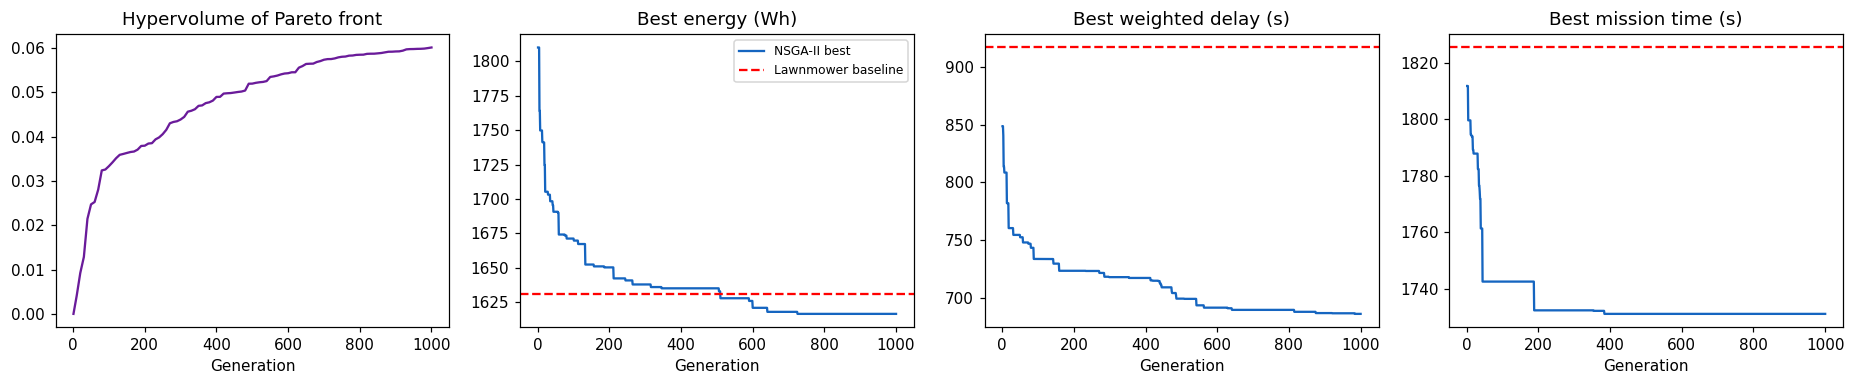

In [10]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
ax[0].plot(tracker.hv_gen, tracker.hv, color="#6a1b9a"); ax[0].set_title("Hypervolume of Pareto front"); ax[0].set_xlabel("Generation")
best = np.array(tracker.best)
for k, (name, base) in enumerate([("Best energy (Wh)", LAWN[0]), ("Best weighted delay (s)", LAWN[1]), ("Best mission time (s)", LAWN[2])]):
    ax[k + 1].plot(tracker.gen, best[:, k], color="#1565c0", label="NSGA-II best")
    ax[k + 1].axhline(base, color="r", ls="--", label="Lawnmower baseline"); ax[k + 1].set_title(name); ax[k + 1].set_xlabel("Generation")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("results/02_convergence.png", dpi=150, bbox_inches="tight"); plt.show()

### 8.2 Pareto front

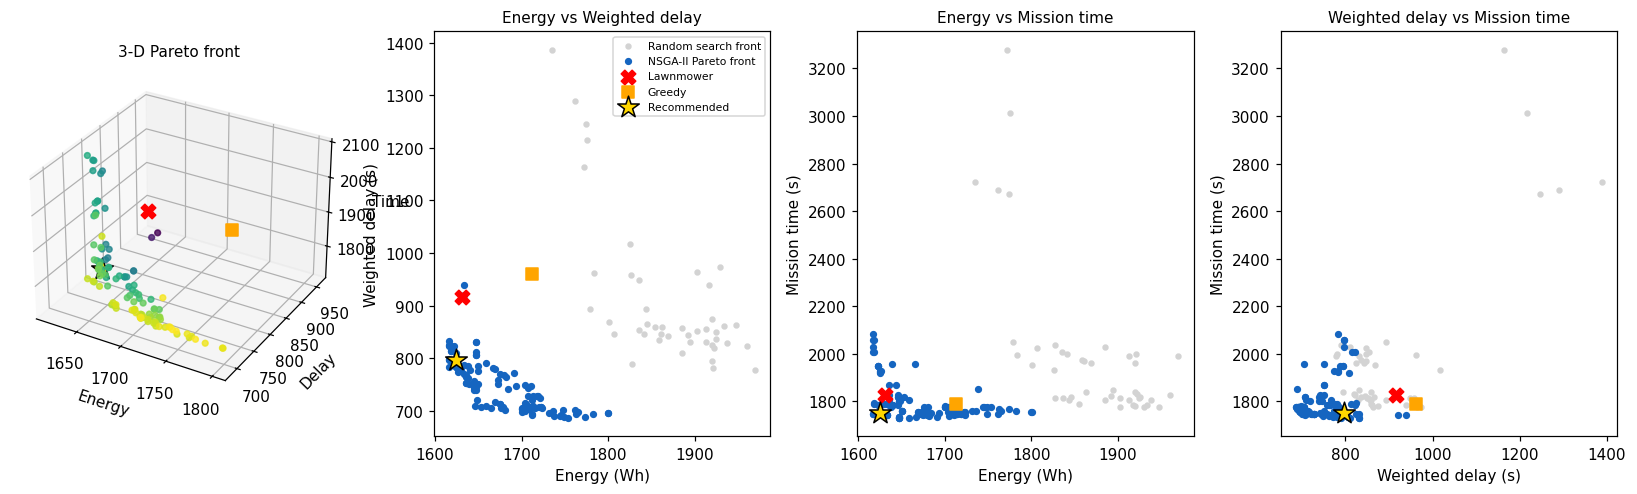

In [11]:
from mpl_toolkits.mplot3d import Axes3D  # noqa
fig = plt.figure(figsize=(15, 4.6))
ax = fig.add_subplot(1, 4, 1, projection="3d")
ax.scatter(*F.T, c=F[:, 1], cmap="viridis_r", s=14, alpha=0.8)
ax.scatter(*LAWN, c="red", marker="X", s=90); ax.scatter(*GREEDY, c="orange", marker="s", s=70); ax.scatter(*F[REC], c="gold", marker="*", s=220, edgecolor="k")
ax.set_xlabel("Energy"); ax.set_ylabel("Delay"); ax.set_zlabel("Time"); ax.set_title("3-D Pareto front", fontsize=10)
for k, (i, j) in enumerate([(0, 1), (0, 2), (1, 2)]):
    a = fig.add_subplot(1, 4, k + 2)
    a.scatter(RS_front[:, i], RS_front[:, j], c="lightgrey", s=10, label="Random search front")
    a.scatter(F[:, i], F[:, j], c="#1565c0", s=14, label="NSGA-II Pareto front")
    a.scatter(LAWN[i], LAWN[j], c="red", marker="X", s=90, label="Lawnmower")
    a.scatter(GREEDY[i], GREEDY[j], c="orange", marker="s", s=70, label="Greedy")
    a.scatter(F[REC][i], F[REC][j], c="gold", marker="*", s=220, edgecolor="k", label="Recommended", zorder=5)
    names = ["Energy (Wh)", "Weighted delay (s)", "Mission time (s)"]
    a.set_xlabel(names[i]); a.set_ylabel(names[j]); a.set_title(f"{names[i].split(' (')[0]} vs {names[j].split(' (')[0]}", fontsize=10)
    if k == 0: a.legend(fontsize=7)
plt.tight_layout(); plt.savefig("results/03_pareto_front.png", dpi=150, bbox_inches="tight"); plt.show()

### 8.3 Flight plans: baselines vs the NSGA-II recommended plan
Numbers on the map show the order in which each drone visits the zones; colours separate the drones. Note how the optimised plan visits the dark-red hotspots early and uses the power-line gaps efficiently.

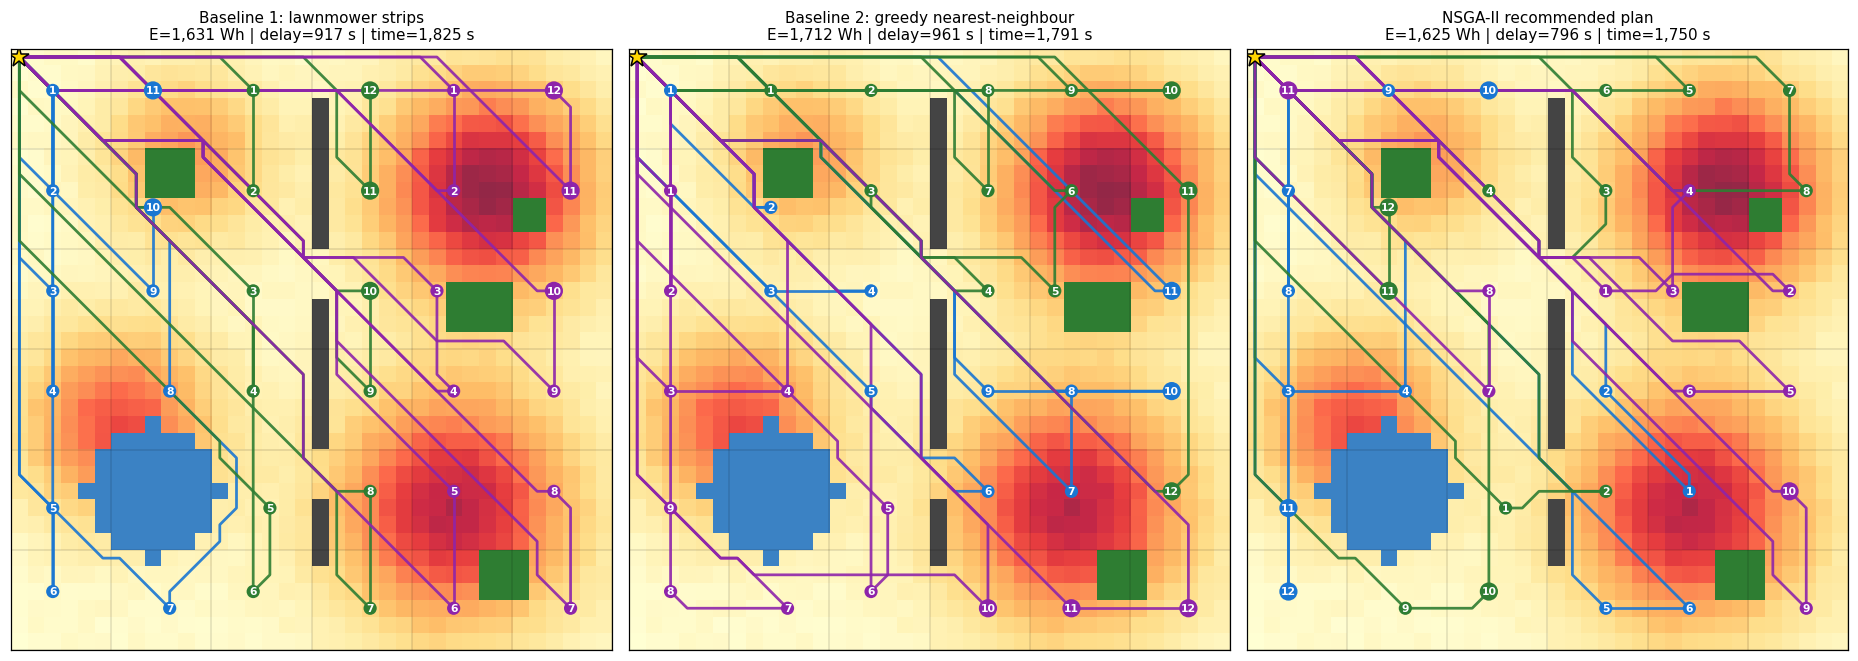

In [12]:
DRONE_COLORS = ["#1976d2", "#2e7d32", "#8e24aa"]
def draw_plan(ax, routes, title):
    (e, w, m), tr = simulate(routes, trace=True)
    draw_field(ax, f"{title}\nE={e:,.0f} Wh | delay={w:,.0f} s | time={m:,.0f} s")
    for d, events in enumerate(tr):
        col = DRONE_COLORS[d % 3]; order = 0
        for kind_, a, b, _t in events:
            if kind_ == "fly":
                p = np.array(PATH[(a, b)]); ax.plot(p[:, 1], p[:, 0], color=col, lw=1.8, alpha=0.9)
            elif kind_ == "spray":
                order += 1; r, c = node_cells[a]
                ax.text(c, r, str(order), color="white", fontsize=7, ha="center", va="center", weight="bold",
                        bbox=dict(boxstyle="circle,pad=0.15", fc=col, ec="none"))

best_routes = decode(X[REC])
fig, axs = plt.subplots(1, 3, figsize=(17, 6))
draw_plan(axs[0], baseline_lawnmower(), "Baseline 1: lawnmower strips")
draw_plan(axs[1], baseline_greedy(), "Baseline 2: greedy nearest-neighbour")
draw_plan(axs[2], best_routes, "NSGA-II recommended plan")
plt.tight_layout(); plt.savefig("results/04_flight_plans.png", dpi=150, bbox_inches="tight"); plt.show()

### 8.4 Objective comparison and mission timeline

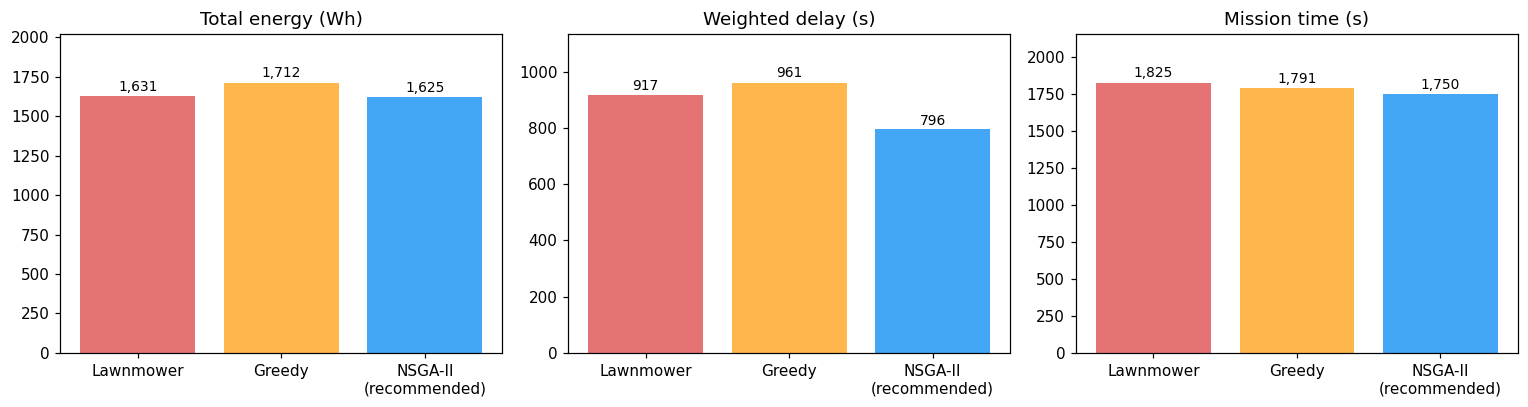

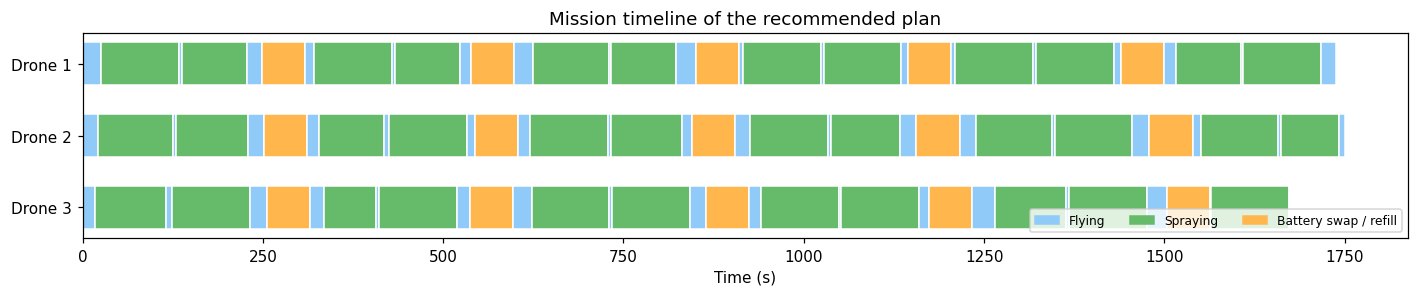

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
labels = ["Lawnmower", "Greedy", "NSGA-II\n(recommended)"]
vals = np.vstack([LAWN, GREEDY, F[REC]])
for k, nm in enumerate(["Total energy (Wh)", "Weighted delay (s)", "Mission time (s)"]):
    bars = ax[k].bar(labels, vals[:, k], color=["#e57373", "#ffb74d", "#42a5f5"])
    ax[k].set_title(nm); ax[k].set_ylim(0, vals[:, k].max() * 1.18)
    for b, v in zip(bars, vals[:, k]):
        ax[k].text(b.get_x() + b.get_width() / 2, v * 1.02, f"{v:,.0f}", ha="center", fontsize=9)
plt.tight_layout(); plt.savefig("results/05_objective_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

# Gantt chart of the recommended plan
_, tr_best = simulate(best_routes, trace=True)
fig, ax = plt.subplots(figsize=(13, 2.8)); colors = {"fly": "#90caf9", "spray": "#66bb6a", "wait": "#ffb74d"}
for d, events in enumerate(tr_best):
    t_prev = 0.0
    for kind_, a, b, t1 in events:
        ax.barh(d, t1 - t_prev, left=t_prev, color=colors[kind_], edgecolor="white", height=0.6); t_prev = t1
ax.set_yticks(range(N_DRONES)); ax.set_yticklabels([f"Drone {d + 1}" for d in range(N_DRONES)]); ax.invert_yaxis()
ax.set_xlabel("Time (s)"); ax.set_title("Mission timeline of the recommended plan")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=colors["fly"], label="Flying"), Patch(color=colors["spray"], label="Spraying"),
                   Patch(color=colors["wait"], label="Battery swap / refill")], ncol=3, fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig("results/06_timeline.png", dpi=150, bbox_inches="tight"); plt.show()

### 8.5 Robustness: repeated runs with different random seeds
Evolutionary algorithms are stochastic, so we repeat a shorter run with 5 different seeds and report the mean and standard deviation.

In [14]:
rob = []
for s in range(1, 6):
    r = minimize(SprayProblem(), make_algorithm(100), ("n_gen", 500), seed=s, verbose=False)
    rob.append([s, hypervolume(r.F), *r.F.min(axis=0)])
rob = pd.DataFrame(rob, columns=["Seed", "Hypervolume", "Best energy", "Best delay", "Best mission time"]).set_index("Seed")
display(rob.round(3))
print("Mean +/- std over 5 seeds (pop 100, 500 generations):")
display(pd.DataFrame({"mean": rob.mean(), "std": rob.std()}).round(3))

,Hypervolume,Best energy,Best delay,Best mission time
Seed,,,,
1,0.047,1622.251,714.215,1738.612
2,0.046,1620.232,714.419,1740.576
3,0.048,1628.287,703.077,1744.013
4,0.046,1637.784,718.466,1733.591
5,0.048,1644.375,701.389,1743.245


Mean +/- std over 5 seeds (pop 100, 500 generations):


,mean,std
Hypervolume,0.047,0.001
Best energy,1630.586,10.294
Best delay,710.313,7.592
Best mission time,1740.007,4.182


## 9. Animated mission (for the LinkedIn post)

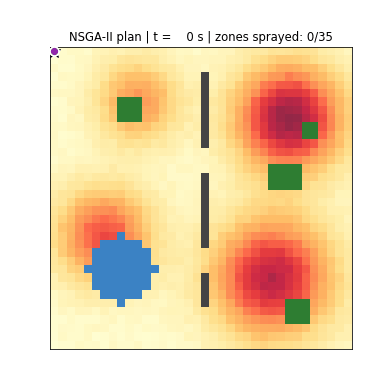

In [15]:
def waypoints(events):
    pts = [(0.0, DEPOT[1], DEPOT[0])]; t0 = 0.0
    for kind_, a, b, t1 in events:
        if kind_ == "fly":
            path = PATH[(a, b)]
            seg = np.array([np.hypot(p[0] - q[0], p[1] - q[1]) for p, q in zip(path[:-1], path[1:])])
            cum = np.concatenate([[0], np.cumsum(seg)]) / seg.sum()
            for (r, c), f in zip(path[1:], cum[1:]):
                pts.append((t0 + f * (t1 - t0), c, r))
        else:
            r, c = node_cells[a]; pts.append((t1, c, r))
        t0 = t1
    return np.array(pts)

(metrics_best, tr_anim) = simulate(best_routes, trace=True)
T_END = metrics_best[2]; N_FR = 90
times = np.linspace(0, T_END * 1.02, N_FR)
tracks = []
for events in tr_anim:
    w = waypoints(events)
    tracks.append((np.interp(times, w[:, 0], w[:, 1]), np.interp(times, w[:, 0], w[:, 2])))
done_time = {}
for events in tr_anim:
    for kind_, a, b, t1 in events:
        if kind_ == "spray": done_time[b] = t1

fig, ax = plt.subplots(figsize=(5.6, 5.6))
draw_field(ax, zone_grid=False)
patches = []
for i, z in enumerate(zones):
    p = Rectangle((z["zc"] * ZB - 0.5, z["zr"] * ZB - 0.5), ZB, ZB, fc="#00c853", ec="k", lw=0.4, alpha=0.0); ax.add_patch(p); patches.append(p)
trails = [ax.plot([], [], color=DRONE_COLORS[d], lw=1.6, alpha=0.8)[0] for d in range(N_DRONES)]
dots = [ax.plot([], [], "o", color=DRONE_COLORS[d], ms=9, mec="white", mew=1.5, zorder=6)[0] for d in range(N_DRONES)]
ttl = ax.set_title("")
def update(f):
    for d in range(N_DRONES):
        trails[d].set_data(tracks[d][0][:f + 1], tracks[d][1][:f + 1]); dots[d].set_data([tracks[d][0][f]], [tracks[d][1][f]])
    n_done = 0
    for i, p in enumerate(patches):
        if done_time[i] <= times[f]: p.set_alpha(0.30); n_done += 1
    ttl.set_text(f"NSGA-II plan | t = {times[f]:4.0f} s | zones sprayed: {n_done}/{Z}")
    return trails + dots + patches + [ttl]
anim = FuncAnimation(fig, update, frames=N_FR, blit=False)
anim.save("results/spraying_mission.gif", writer=PillowWriter(fps=12), dpi=70)
plt.close(fig)
from IPython.display import Image
Image(filename="results/spraying_mission.gif")

## 10. Save results (CSV / JSON) and download everything

In [16]:
pf = pd.DataFrame(F, columns=["energy_Wh", "weighted_delay_s", "mission_time_s"])
pf["route_chromosome"] = [" ".join(map(str, x)) for x in X]
pf.sort_values("weighted_delay_s").to_csv("results/pareto_front.csv", index=False)
table.round(2).to_csv("results/comparison_table.csv")
summary = {"zones": Z, "evaluations": POP_SIZE * N_GEN, "runtime_s": round(RUNTIME, 1),
           "pareto_size": int(len(F)), "hypervolume_nsga2": round(hypervolume(F), 4), "hypervolume_random": round(hypervolume(RS_front), 4),
           "recommended": dict(zip(["energy_Wh", "weighted_delay_s", "mission_time_s"], map(float, F[REC].round(1)))),
           "lawnmower": dict(zip(["energy_Wh", "weighted_delay_s", "mission_time_s"], map(float, LAWN.round(1)))),
           "greedy": dict(zip(["energy_Wh", "weighted_delay_s", "mission_time_s"], map(float, GREEDY.round(1)))),
           "change_vs_lawnmower_pct": dict(zip(["energy", "delay", "time"], map(float, imp["vs Lawnmower (%)"]))),
           "change_vs_greedy_pct": dict(zip(["energy", "delay", "time"], map(float, imp["vs Greedy (%)"])))}
json.dump(summary, open("results/summary.json", "w"), indent=2)

print("LINKEDIN-READY RESULT LINE")
print(f"Compared with the standard strip-sweep plan, the NSGA-II plan sprays disease hotspots "
      f"{-imp.loc['Weighted delay', 'vs Lawnmower (%)']:.0f}% earlier "
      f"(weighted delay), changes energy by {imp.loc['Energy', 'vs Lawnmower (%)']:+.1f}% and mission time by "
      f"{imp.loc['Mission time', 'vs Lawnmower (%)']:+.1f}%; versus greedy nearest-neighbour: "
      f"{-imp.loc['Weighted delay', 'vs Greedy (%)']:.0f}% earlier hotspot treatment, "
      f"{imp.loc['Energy', 'vs Greedy (%)']:+.1f}% energy, {imp.loc['Mission time', 'vs Greedy (%)']:+.1f}% mission time.")
print(json.dumps(summary, indent=2))

import shutil; shutil.make_archive("results_package", "zip", "results")
try:
    from google.colab import files; files.download("results_package.zip")     # works only inside Colab
except Exception:
    print("Not running in Colab: results are in the 'results/' folder.")

LINKEDIN-READY RESULT LINE
Compared with the standard strip-sweep plan, the NSGA-II plan sprays disease hotspots 13% earlier (weighted delay), changes energy by -0.4% and mission time by -4.1%; versus greedy nearest-neighbour: 17% earlier hotspot treatment, -5.1% energy, -2.3% mission time.
{
  "zones": 35,
  "evaluations": 200000,
  "runtime_s": 75.7,
  "pareto_size": 111,
  "hypervolume_nsga2": 0.0601,
  "hypervolume_random": 0.0056,
  "recommended": {
    "energy_Wh": 1624.6,
    "weighted_delay_s": 795.6,
    "mission_time_s": 1750.3
  },
  "lawnmower": {
    "energy_Wh": 1630.8,
    "weighted_delay_s": 916.9,
    "mission_time_s": 1825.4
  },
  "greedy": {
    "energy_Wh": 1712.5,
    "weighted_delay_s": 960.9,
    "mission_time_s": 1791.0
  },
  "change_vs_lawnmower_pct": {
    "energy": -0.4,
    "delay": -13.2,
    "time": -4.1
  },
  "change_vs_greedy_pct": {
    "energy": -5.1,
    "delay": -17.2,
    "time": -2.3
  }
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Discussion and conclusion
* **What worked:** NSGA-II returns a whole set of mission plans, many of which **dominate both baselines** (better or equal in every objective, strictly better in at least one). It also clearly beats random search with the same evaluation budget (hypervolume comparison above).
* **Biggest gain:** the priority-weighted delay. The baselines ignore where the disease is, while the evolved plans send drones to hotspots first.
* **Energy and mission time:** these improve only modestly. Spraying energy is fixed by the area to cover, and strip sweeping is already a strong energy-saving heuristic, so there is limited room to improve energy.
* **Trade-off:** the plan with the very best delay is not the plan with the least energy; the Pareto front shows the farmer exactly how much of one must be given up for the other.
* **Limitations:** zone-level (not row-by-row) planning; constant wind; no battery degradation, payload-weight effect or drone-to-drone collision avoidance; synthetic disease map.
* **Future work:** a memetic variant (local search on routes), real NDVI/multispectral maps, time-varying wind, and a many-objective version with chemical-dose limits.

## 12. References
1. K. Deb, A. Pratap, S. Agarwal, T. Meyarivan, "A fast and elitist multiobjective genetic algorithm: NSGA-II," *IEEE Transactions on Evolutionary Computation*, 6(2), 182-197, 2002.
2. J. Blank and K. Deb, "pymoo: Multi-objective Optimization in Python," *IEEE Access*, 8, 89497-89509, 2020.
3. T. Hanne and M. J. Moghaddam, “A review of the evolution of multi-objective evolutionary algorithms,” Computers, Materials & Continua, vol. 85, no. 3, pp. 4203–4236, 2025, doi: 10.32604/cmc.2025.068087.
4. E. Galceran and M. Carreras, "A survey on coverage path planning for robotics," *Robotics and Autonomous Systems*, 61(12), 1258-1276, 2013.
5. Rahman, M., Sarkar, N. I., & Lutui, R. (2025). A Survey on Multi-UAV Path Planning: Classification, Algorithms, Open Research Problems, and Future Directions. Drones, 9(4), 263. https://doi.org/10.3390/drones9040263
6. C. A. Coello Coello, G. B. Lamont, D. A. Van Veldhuizen, *Evolutionary Algorithms for Solving Multi-Objective Problems*, 2nd ed., Springer, 2007.
7. A. García-Munguía, P. L. Guerra-Ávila, E. Islas-Ojeda, J. L. Flores-Sánchez, O. Vázquez-Martínez, A. M. García-Munguía, and O. García-Munguía, “A review of drone technology and operation processes in agricultural crop spraying,” Drones, vol. 8, no. 11, Art. no. 674, 2024, doi: 10.3390/drones8110674.
8. A. Hafeez, M. A. Husain, S. P. Singh, A. Chauhan, M. T. Khan, N. Kumar, A. Chauhan, and S. K. Soni, “Implementation of drone technology for farm monitoring & pesticide spraying: A review,” Information Processing in Agriculture, vol. 10, no. 2, pp. 192–203, 2023, doi: 10.1016/j.inpa.2022.02.002.